# Task 1: Lounge eligibility at Heathrow Terminal 3

**Goal:** build a lookup table that estimates what share of passengers on a flight are eligible for each British Airways lounge tier, so the Airport Planning team can estimate lounge demand for future schedules without knowing exact flights or aircraft.

| Tier | Lounge | Who can use it |
|---|---|---|
| 1 | Concorde Room | First Class customers, BA Premier cardholders, Gold Guest List members |
| 2 | First Lounge | BA Gold members |
| 3 | Club Lounge | BA Silver cardholders, Club World (business class) customers |

There is no Concorde Room at Terminal 3 today, so Tier 1 is treated as **hypothetical demand**.

Steps:
1. Explore the schedule
2. Choose flight groups
3. Set first-guess assumptions
4. Test them on a sample week
5. Revise them using the full dataset and check the final lookup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
NAVY, RED, GREY = "#0B1F45", "#C8102E", "#9AA3AF"
TIERS = ["TIER1_ELIGIBLE_PAX", "TIER2_ELIGIBLE_PAX", "TIER3_ELIGIBLE_PAX"]

df = pd.read_excel("../data/British_Airways_Summer_Schedule_Dataset.xlsx")
print(df.shape)
df.head()

(10000, 17)


,FLIGHT_DATE,FLIGHT_TIME,TIME_OF_DAY,AIRLINE_CD,FLIGHT_NO,DEPARTURE_STATION_CD,ARRIVAL_STATION_CD,ARRIVAL_COUNTRY,ARRIVAL_REGION,HAUL,AIRCRAFT_TYPE,FIRST_CLASS_SEATS,BUSINESS_CLASS_SEATS,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
0,2025-09-02,14:19:00,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,10,38
1,2025-06-10,06:42:00,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,7,28
2,2025-10-27,15:33:00,Afternoon,BA,BA1896,LHR,FRA,Germany,Europe,SHORT,A320,0,17,163,0,11,40
3,2025-06-15,18:29:00,Evening,BA,BA5497,LHR,IST,Turkey,Europe,SHORT,A320,0,8,172,0,16,54
4,2025-08-25,20:35:00,Evening,BA,BA1493,LHR,FRA,Germany,Europe,SHORT,A320,0,13,167,0,6,27


## 1. Explore the schedule

In [2]:
print("Dates:", df["FLIGHT_DATE"].min().date(), "to", df["FLIGHT_DATE"].max().date())
for col in ["HAUL", "TIME_OF_DAY", "ARRIVAL_REGION", "AIRCRAFT_TYPE"]:
    print(df[col].value_counts(), "\n")

Dates: 2025-04-01 to 2025-10-30
HAUL
SHORT    5975
LONG     4025
Name: count, dtype: int64 

TIME_OF_DAY
Morning      3530
Evening      2973
Afternoon    2305
Lunchtime    1192
Name: count, dtype: int64 

ARRIVAL_REGION
Europe           5975
North America    2658
Middle East       688
Asia              679
Name: count, dtype: int64 

AIRCRAFT_TYPE
A320    5975
B777    1878
B787    1236
A350     535
A380     376
Name: count, dtype: int64 



10,000 departures from Heathrow between April and October 2025. Each row has the seat count by cabin and the number of passengers eligible for each lounge tier.

There's no load factor in the data, so **total passengers = total seats** throughout.

In [3]:
df["SEATS"] = df["FIRST_CLASS_SEATS"] + df["BUSINESS_CLASS_SEATS"] + df["ECONOMY_SEATS"]
df.groupby(["HAUL", "AIRCRAFT_TYPE"])[["FIRST_CLASS_SEATS", "BUSINESS_CLASS_SEATS", "ECONOMY_SEATS", "SEATS"]].mean().round(0)

FIRST_CLASS_SEATS  BUSINESS_CLASS_SEATS  ECONOMY_SEATS  SEATS
HAUL  AIRCRAFT_TYPE                                                               
LONG  A350                         0.0                  56.0          275.0  331.0
      A380                        14.0                  97.0          358.0  469.0
      B777                         3.0                  40.0          247.0  290.0
      B787                         4.0                  39.0          180.0  224.0
SHORT A320                         0.0                  10.0          170.0  180.0

## 2. Choose flight groups

I grouped flights by **haul type** and **departure time**:
- Haul is known long before exact aircraft or flight numbers, and it sets the size of the premium cabins.
- Time of day reflects the mix of business and leisure travellers.

Time bands: Morning (before 12:00), Afternoon (12:00–17:59), Evening (18:00 onwards). The dataset's "Lunchtime" band is folded into Afternoon to keep the table small. That gives six groups.

In [4]:
hour = pd.to_datetime(df["FLIGHT_TIME"].astype(str), format="%H:%M:%S").dt.hour
df["TIME_BAND"] = pd.cut(hour, bins=[-1, 11, 17, 23], labels=["Morning", "Afternoon", "Evening"]).astype(str)
df["HAUL_GROUP"] = df["HAUL"].map({"LONG": "Long-haul", "SHORT": "Short-haul"})
df["GROUP"] = df["HAUL_GROUP"] + " - " + df["TIME_BAND"]
df["GROUP"].value_counts()

GROUP
Short-haul - Afternoon    2123
Short-haul - Morning      2069
Short-haul - Evening      1783
Long-haul - Morning       1461
Long-haul - Afternoon     1374
Long-haul - Evening       1190
Name: count, dtype: int64

## 3. First-guess assumptions

Before looking at the eligibility columns, I set rough percentages based on how I expected passengers to behave:
- Long-haul has bigger premium cabins, so higher shares in every tier
- Short-haul has no First Class, so Tier 1 comes only from Premier and Gold Guest List members
- Morning flights carry the most business travellers, so mornings peak
- Afternoon flights carry more leisure passengers, so they're lowest

In [5]:
initial = pd.DataFrame({
    "GROUP": ["Long-haul - Morning", "Long-haul - Afternoon", "Long-haul - Evening",
              "Short-haul - Morning", "Short-haul - Afternoon", "Short-haul - Evening"],
    "T1": [0.030, 0.020, 0.025, 0.008, 0.005, 0.006],
    "T2": [0.060, 0.045, 0.050, 0.030, 0.020, 0.025],
    "T3": [0.160, 0.140, 0.150, 0.080, 0.055, 0.070],
}).set_index("GROUP")
initial.style.format("{:.1%}")

,T1,T2,T3
GROUP,,,
Long-haul - Morning,3.0%,6.0%,16.0%
Long-haul - Afternoon,2.0%,4.5%,14.0%
Long-haul - Evening,2.5%,5.0%,15.0%
Short-haul - Morning,0.8%,3.0%,8.0%
Short-haul - Afternoon,0.5%,2.0%,5.5%
Short-haul - Evening,0.6%,2.5%,7.0%


## 4. Test on a sample week

The task asks for a representative sample rather than every flight. I used one full week, **14–20 July 2025** (312 flights). It covers every day of the week and all six groups.

In [6]:
def eligible_share(data):
    g = data.groupby("GROUP")[["SEATS"] + TIERS].sum()
    out = g[TIERS].div(g["SEATS"], axis=0)
    out.columns = ["T1", "T2", "T3"]
    return out.loc[initial.index]

sample = df[(df["FLIGHT_DATE"] >= "2025-07-14") & (df["FLIGHT_DATE"] <= "2025-07-20")].copy()
print("Flights in sample week:", len(sample))

sample_actual = eligible_share(sample)
compare = pd.concat({"Assumed": initial, "Actual (sample week)": sample_actual}, axis=1)
compare.style.format("{:.1%}")

Flights in sample week: 312


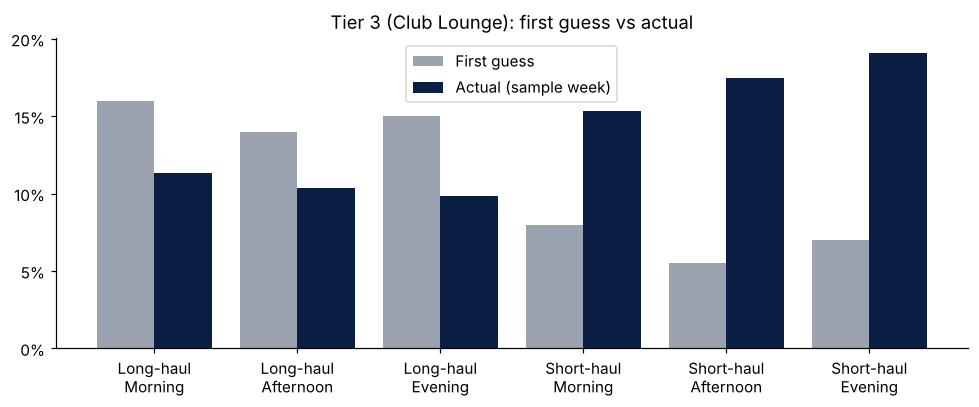

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(initial))
ax.bar([i - 0.2 for i in x], initial["T3"], width=0.4, color=GREY, label="First guess")
ax.bar([i + 0.2 for i in x], sample_actual["T3"], width=0.4, color=NAVY, label="Actual (sample week)")
ax.set_xticks(list(x)); ax.set_xticklabels([g.replace(" - ", "\n") for g in initial.index])
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05)); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Tier 3 (Club Lounge): first guess vs actual"); ax.legend()
plt.tight_layout(); plt.savefig("images/first_guess_vs_actual.png", bbox_inches="tight", dpi=200); plt.show()

The first guesses didn't hold up:
- **Short-haul has a higher eligible share than long-haul**, the opposite of what I assumed. Short-haul aircraft are small (about 180 seats) and carry many frequent European business travellers, so status holders make up more of each flight. Long-haul aircraft have large economy cabins that are mostly leisure passengers.
- **Tier 1 and Tier 2 were overestimated on long-haul.**
- **Time of day makes much less difference than expected.**

So I revised the assumptions using the data.

## 5. Revise the assumptions

In [8]:
full_actual = eligible_share(df)
full_actual.style.format("{:.2%}")

,T1,T2,T3
GROUP,,,
Long-haul - Morning,0.21%,2.79%,10.63%
Long-haul - Afternoon,0.19%,2.75%,10.48%
Long-haul - Evening,0.21%,2.67%,10.26%
Short-haul - Morning,0.34%,4.36%,16.74%
Short-haul - Afternoon,0.36%,4.40%,16.83%
Short-haul - Evening,0.33%,4.45%,17.00%


Within each haul type, the shares change by less than 1 percentage point across the day. Haul is the main driver.

I also checked whether grouping by **region** would add anything:

In [9]:
r = df.groupby(["ARRIVAL_REGION", "HAUL"])[["SEATS"] + TIERS].sum()
r[TIERS].div(r["SEATS"], axis=0).rename(columns=dict(zip(TIERS, ["T1", "T2", "T3"]))).style.format("{:.2%}")

,,T1,T2,T3
ARRIVAL_REGION,HAUL,,,
Asia,LONG,0.19%,2.70%,10.35%
Europe,SHORT,0.34%,4.40%,16.85%
Middle East,LONG,0.21%,2.69%,10.29%
North America,LONG,0.20%,2.76%,10.55%


Every Europe flight is short-haul and every other region is long-haul, so region gives the same split as haul. The three long-haul regions are almost identical, so I didn't add region as a grouping.

**Final lookup table** (revised assumptions, rounded to one decimal place):

In [10]:
# full-dataset shares rounded to one decimal place (the values submitted in the Excel template)
lookup = pd.DataFrame({
    "T1": [0.002, 0.002, 0.002, 0.003, 0.004, 0.003],
    "T2": [0.028, 0.027, 0.027, 0.044, 0.044, 0.045],
    "T3": [0.106, 0.105, 0.103, 0.167, 0.168, 0.170],
}, index=initial.index)
lookup.style.format("{:.1%}")

,T1,T2,T3
GROUP,,,
Long-haul - Morning,0.2%,2.8%,10.6%
Long-haul - Afternoon,0.2%,2.7%,10.5%
Long-haul - Evening,0.2%,2.7%,10.3%
Short-haul - Morning,0.3%,4.4%,16.7%
Short-haul - Afternoon,0.4%,4.4%,16.8%
Short-haul - Evening,0.3%,4.5%,17.0%


### Check the final lookup on all 10,000 flights

Apply the rounded lookup to every flight (seats × group percentage) and compare with the actual eligible passengers.

In [11]:
est = df[["GROUP", "SEATS"] + TIERS].copy()
for t, col in zip(["T1", "T2", "T3"], TIERS):
    est["EST_" + t] = est["SEATS"] * est["GROUP"].map(lookup[t])

check = est.groupby("GROUP")[["EST_T1", "TIER1_ELIGIBLE_PAX", "EST_T2", "TIER2_ELIGIBLE_PAX", "EST_T3", "TIER3_ELIGIBLE_PAX"]].sum().loc[initial.index]
check.loc["All flights"] = check.sum()
for t, col in zip(["T1", "T2", "T3"], TIERS):
    check["DIFF_" + t] = check["EST_" + t] / check[col] - 1
check.style.format({c: "{:,.0f}" for c in check.columns if not c.startswith("DIFF")} | {c: "{:+.1%}" for c in check.columns if c.startswith("DIFF")})

,EST_T1,TIER1_ELIGIBLE_PAX,EST_T2,TIER2_ELIGIBLE_PAX,EST_T3,TIER3_ELIGIBLE_PAX,DIFF_T1,DIFF_T2,DIFF_T3
GROUP,,,,,,,,,
Long-haul - Morning,853,876,"11,944","11,897","45,216","45,356",-2.6%,+0.4%,-0.3%
Long-haul - Afternoon,802,768,"10,823","11,016","42,088","42,000",+4.4%,-1.8%,+0.2%
Long-haul - Evening,694,736,"9,374","9,285","35,758","35,634",-5.7%,+1.0%,+0.3%
Short-haul - Morning,"1,117","1,266","16,386","16,230","62,194","62,354",-11.7%,+1.0%,-0.3%
Short-haul - Afternoon,"1,529","1,377","16,814","16,804","64,200","64,324",+11.0%,+0.1%,-0.2%
Short-haul - Evening,963,"1,054","14,442","14,287","54,560","54,546",-8.7%,+1.1%,+0.0%
All flights,"5,958","6,077","79,783","79,519","304,015","304,214",-2.0%,+0.3%,-0.1%


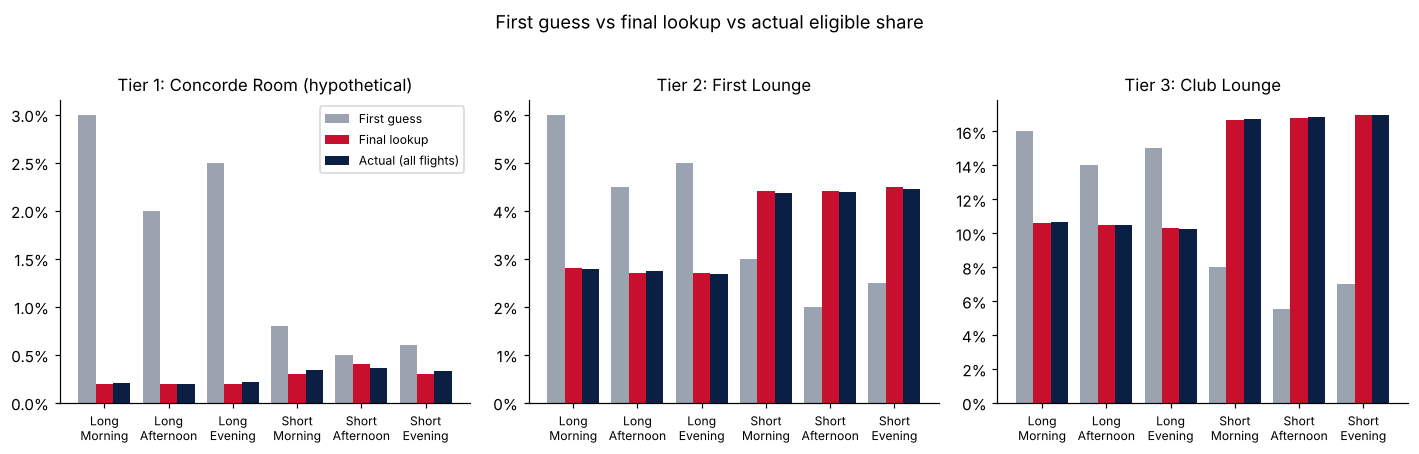

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
x = range(len(initial)); w = 0.27
for ax, t, title in zip(axes, ["T1", "T2", "T3"],
                        ["Tier 1: Concorde Room (hypothetical)", "Tier 2: First Lounge", "Tier 3: Club Lounge"]):
    ax.bar([i - w for i in x], initial[t], width=w, color=GREY, label="First guess")
    ax.bar(list(x), lookup[t], width=w, color=RED, label="Final lookup")
    ax.bar([i + w for i in x], full_actual[t], width=w, color=NAVY, label="Actual (all flights)")
    ax.set_xticks(list(x)); ax.set_xticklabels([g.replace("-haul - ", "\n") for g in initial.index], fontsize=8)
    fmt = "{:.1%}" if t == "T1" else "{:.0%}"
    ax.yaxis.set_major_formatter(lambda v, _, fmt=fmt: fmt.format(v))
    ax.set_title(title, fontsize=11)
axes[0].legend(fontsize=8)
plt.suptitle("First guess vs final lookup vs actual eligible share", y=1.02)
plt.tight_layout(); plt.savefig("images/final_vs_actual.png", bbox_inches="tight", dpi=200); plt.show()

The final lookup (red) sits almost exactly on the actual figures (navy), while the first guesses (grey) were far off, especially on short-haul. Overall, the estimates are within about 2% of the real numbers for every tier. Tier 2 and Tier 3 are within about 2% for each group too. Tier 1 per group is off by up to about 12%, because its numbers are so small that rounding to one decimal place matters.

### Typical daily demand

The dataset holds about 48 departures a day, so these are daily figures for the flights in the dataset, not for the whole of Terminal 3.

In [13]:
days = df["FLIGHT_DATE"].nunique()
daily = df[TIERS].sum() / days
print(f"Average per day across {days} days:")
print(daily.rename(dict(zip(TIERS, ["Tier 1 (hypothetical)", "Tier 2", "Tier 3"]))).round(0))

Average per day across 210 days:
Tier 1 (hypothetical)      29.0
Tier 2                    379.0
Tier 3                   1449.0
dtype: float64


## Summary

- **Grouping:** haul type × time of day (six groups). Both are known for any future schedule.
- **Main finding:** haul type drives eligibility. Short-haul has a higher eligible share than long-haul (Tier 3 about 17% vs 10.5%). Time of day and region add very little.
- **First guesses were tested and revised.** The original assumptions expected long-haul to be higher and mornings to peak, and the data showed neither.
- **Tier 1 is hypothetical.** There's no Concorde Room at Terminal 3, so these figures show passengers who would qualify, which could help BA decide whether a Tier 1 lounge is worth considering.
- **How to use it:** assign each future flight to a group, multiply its seats by that group's percentages, and add up the results.

**Limitations:** summer schedule only (no seasonality), no load factor, and no adjustment for connecting passengers or how long people stay in the lounge.

The submitted lookup table and justification are in `Lounge_Eligibility_Lookup_Task_1.xlsx`.